In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
#Importing my data
positive_points = np.array([[-2, 3], [0, 1], [2, -1]])
negative_points = np.array([[-2, 1], [0, -1], [2, -3]])

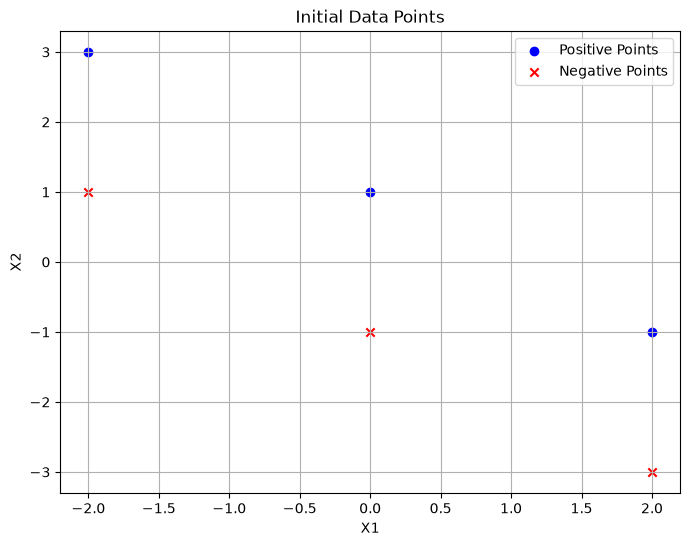

In [3]:
#Plotting the data
plt.figure(figsize=(8, 6))
plt.scatter(positive_points[:, 0], positive_points[:, 1], color='blue', marker='o', label='Positive Points')
plt.scatter(negative_points[:, 0], negative_points[:, 1], color='red', marker='x', label='Negative Points')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Initial Data Points')
plt.grid(True)
plt.legend(loc='best')
plt.show()

In [4]:
#Combining all the data
X = np.vstack((positive_points, negative_points))
y = np.array([1] * len(positive_points) + [-1] * len(negative_points))

In [5]:
X

array([[-2,  3],
       [ 0,  1],
       [ 2, -1],
       [-2,  1],
       [ 0, -1],
       [ 2, -3]])

In [6]:
y

array([ 1,  1,  1, -1, -1, -1])

In [7]:
#Running the perceptron algorithm
def perceptron(X, y, steps=10):
    theta = np.zeros(X.shape[1])
    theta0 = 0
    for t in range(steps):
        for i, xi in enumerate(X):
            if y[i] * (np.dot(theta, xi) + theta0) <= 0:
                theta += y[i] * xi
                theta0 += y[i]
                break
            #plot after each iteration
        plot_decision_boundary(theta, theta0, t)
    return theta, theta0

In [8]:
def plot_decision_boundary(theta, theta0, iteration):
    plt.figure(figsize=(8, 6))
    plt.scatter(positive_points[:, 0], positive_points[:, 1], color='blue', marker='o', label='Positive Points')
    plt.scatter(negative_points[:, 0], negative_points[:, 1], color='red', marker='x', label='Negative Points')
    #plotting the decision boundary
    x_values = np.linspace(-3, 3, 2)
    #check for theta[1] to avoid division by zero in case of vertical line
    if theta[1] != 0:
        y_values = -(theta[0] * x_values + theta0) / theta[1]
        plt.plot(x_values, y_values, label=f'Iteration {iteration}')
    else:
        #plot vertical line if theta[1] is zero  
        x_val = -theta0 / theta[0]
        plt.axvline(x=x_val, label=f'Iteration {iteration}')
        
          
    plt.xlim(-3, 3)
    plt.ylim(-4, 4) 
    plt.xlabel('X1')
    plt.ylabel('X2')    
    plt.title(f'Decision Boundary after Iteration {iteration}')
    plt.grid(True)  
    plt.legend()
    plt.show()

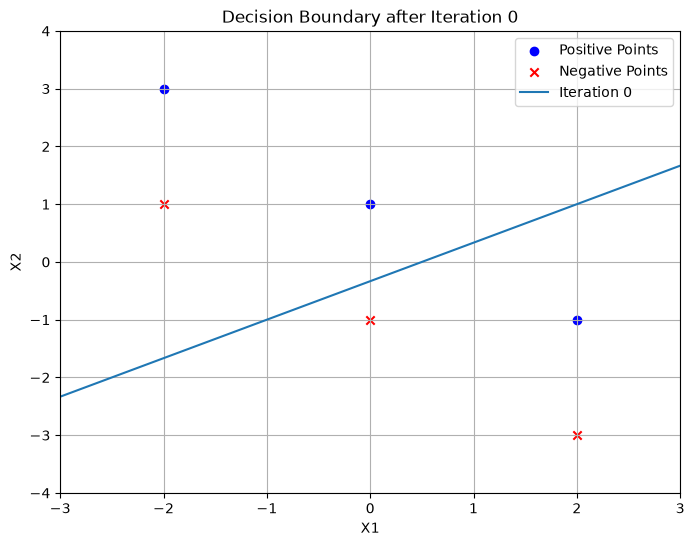

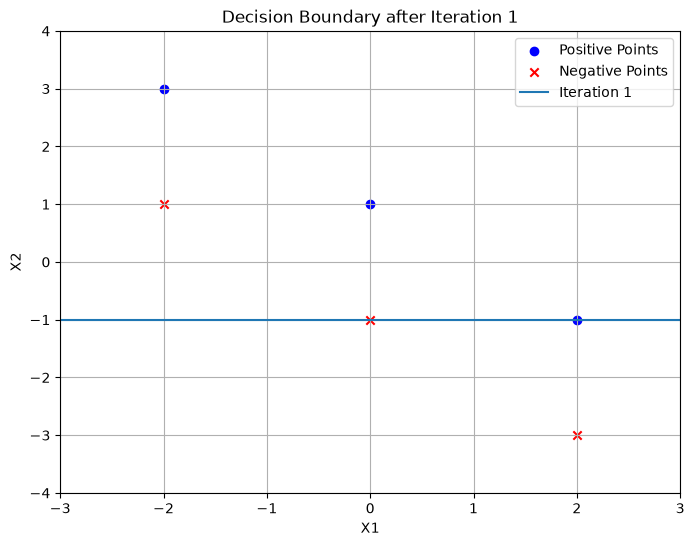

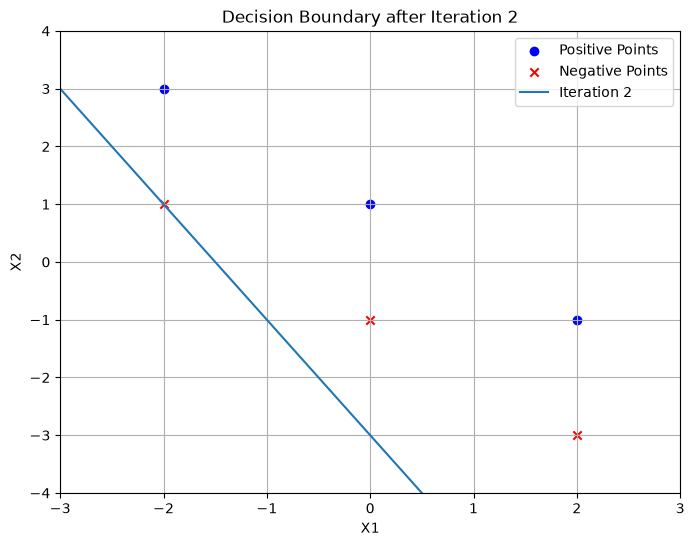

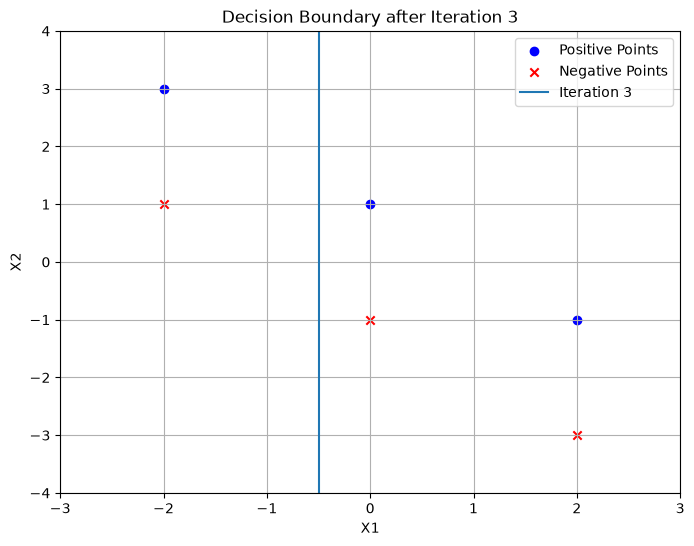

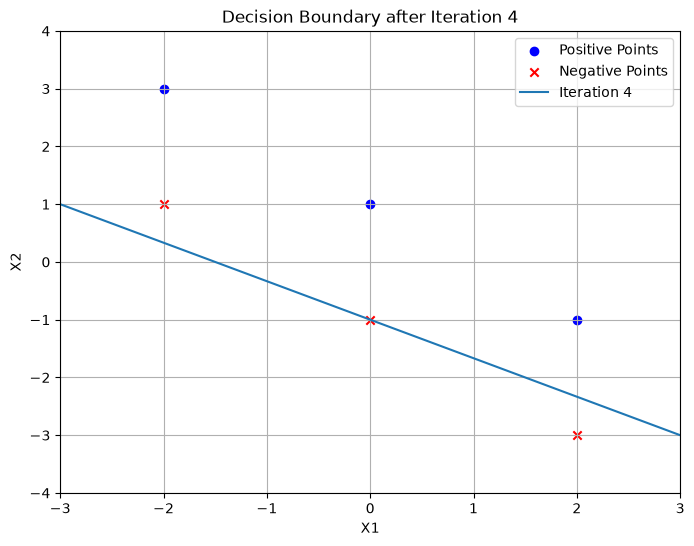

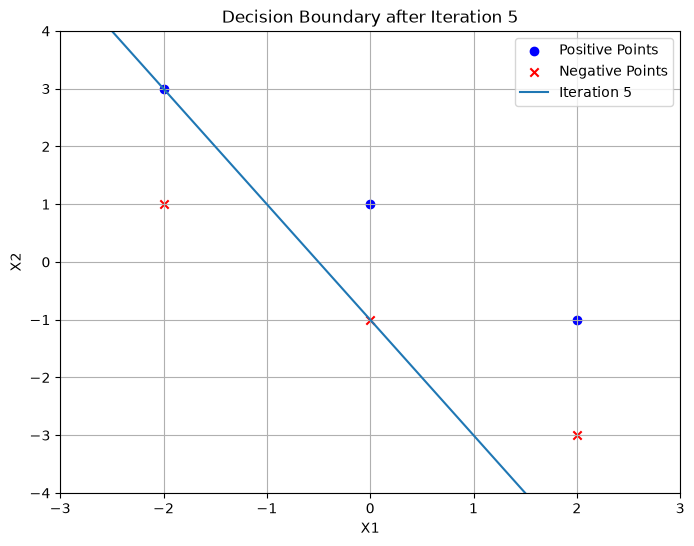

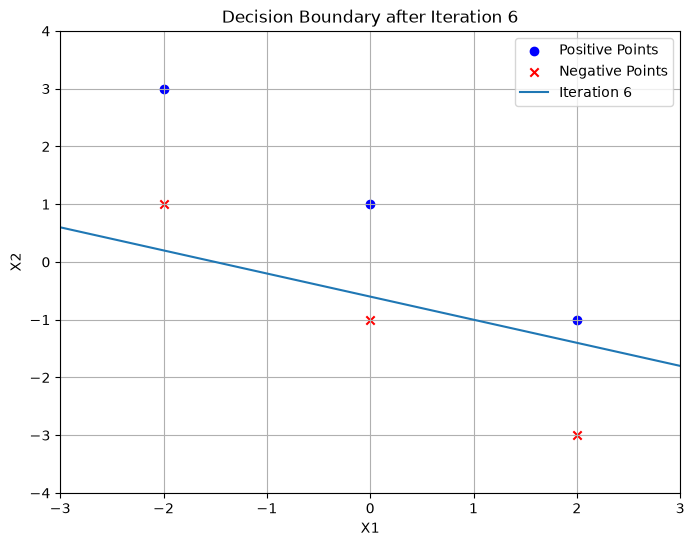

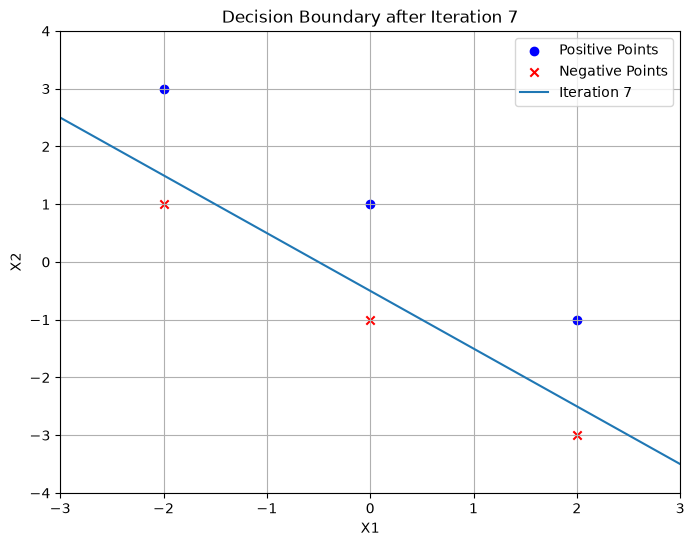

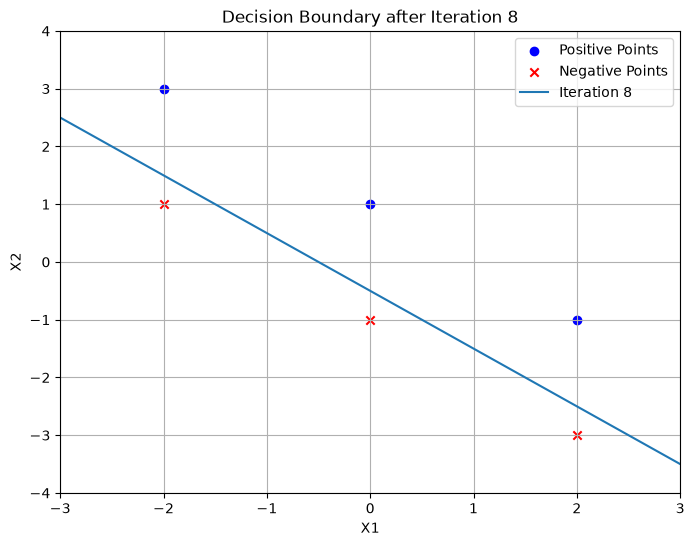

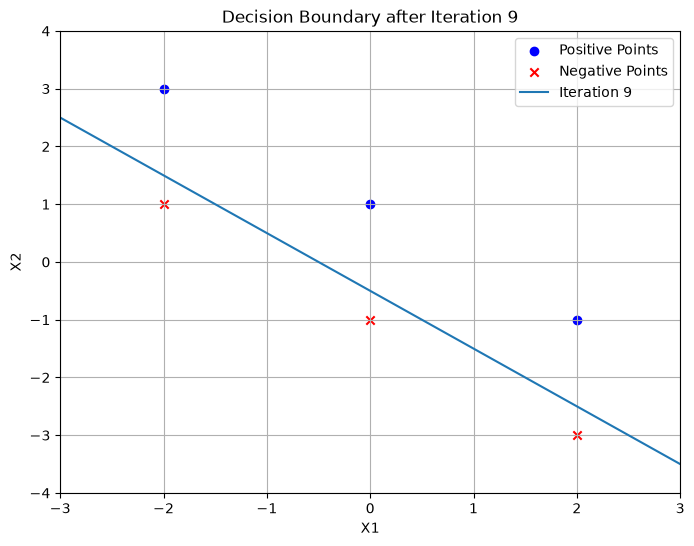

In [9]:
theta_final, theta0_final = perceptron(X, y, steps=10)